# 03 - Base Line Model

In [6]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve()

if ROOT.name == "notebooks":
    ROOT = ROOT.parent

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

In [8]:
import pandas as pd

df = pd.read_csv("../data/processed/midfielder_clusters.csv")

for cluster in sorted(df["cluster"].unique()):
    print(f"\n{'='*40}")
    print(f"CLUSTER {cluster}")
    print(f"{'='*40}")

    players = df[df["cluster"] == cluster]

    display(
        players[
            [
                "player_name",
                "minutes_played",
                "scoring.expected_goals_per90",
                "scoring.expected_assists_per90",
                "defending.tackles_per90",
                "defending.interceptions_per90"
            ]
        ].sort_values(
            "scoring.expected_assists_per90",
            ascending=False
        ).head(10)
    )


CLUSTER 0


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90
58,Rayan Cherki,1794,0.197157,0.412876,1.304348,0.351171
60,Bruno Fernandes,3066,0.303229,0.378082,1.585127,0.587084
12,David Brooks,1220,0.449262,0.235328,1.401639,0.295082
56,Enzo Fernández,3121,0.311439,0.199840,1.528356,0.605575
57,Phil Foden,2107,0.251590,0.194352,1.452302,0.384433
53,Florian Wirtz,2388,0.256658,0.186935,1.281407,0.414573
13,Justin Kluivert,951,0.211041,0.151420,0.946372,0.378549
2,Eberechi Eze,1900,0.229737,0.129789,0.900000,0.521053
5,Mikel Merino,1035,0.284348,0.122609,2.260870,0.869565
21,Jack Hinshelwood,1750,0.243771,0.115200,0.977143,0.257143



CLUSTER 1


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90
31,Adam Wharton,2562,0.051639,0.250117,2.459016,0.948478
17,Mathias Jensen,2277,0.085375,0.229644,1.620553,0.830040
3,Martin Ødegaard,1370,0.078175,0.229270,1.248175,0.459854
18,Mikkel Damsgaard,2078,0.108277,0.226083,2.468720,1.082772
22,Pascal Groß,1636,0.076467,0.218949,1.595355,0.660147
1,Declan Rice,3099,0.088577,0.194288,2.032914,1.074540
86,Xavi Simons,1769,0.149576,0.187224,1.729791,0.763143
52,Dominik Szoboszlai,3233,0.129168,0.180668,1.558924,0.835138
38,Kiernan Dewsbury-Hall,2635,0.142087,0.176926,1.776091,0.409867
0,Bruno Guimarães,2455,0.196864,0.174501,2.272912,0.549898



CLUSTER 2


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90
50,Sean Longstaff,1046,0.104111,0.158317,3.269598,1.032505
65,Youri Tielemans,1862,0.054619,0.154672,2.803437,0.870032
37,James Garner,3414,0.051406,0.149736,3.163445,1.555360
19,Vitaly Janelt,1449,0.054037,0.136646,1.677019,1.863354
55,Elliot Anderson,3334,0.075315,0.123635,2.807439,1.106779
46,Ao Tanaka,1326,0.103846,0.095701,1.832579,1.425339
83,Mateus Fernandes,3024,0.056548,0.083929,3.065476,1.041667
25,Josh Cullen,1519,0.051547,0.077024,1.836735,1.303489
72,Ibrahim Sangaré,2080,0.047163,0.074423,2.552885,1.081731
29,Moisés Caicedo,2802,0.044004,0.073233,2.794433,1.895075


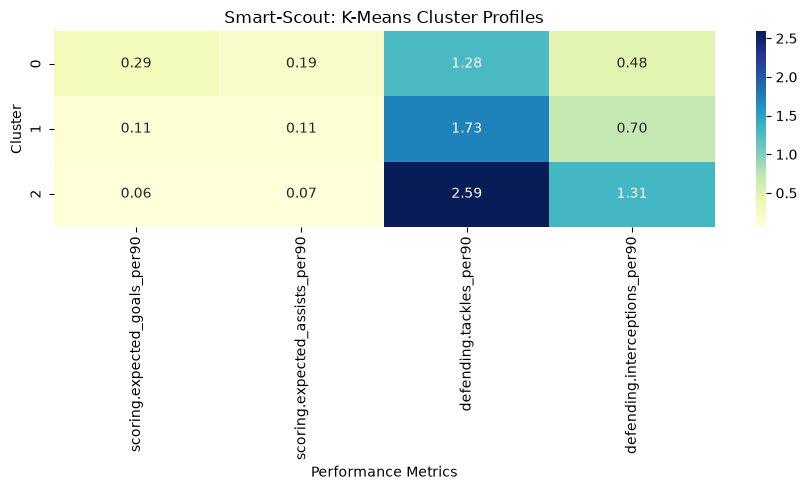

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns 
from src.preprocessing import MODEL_FEATURES

features = [
    "scoring.expected_goals",
    "scoring.expected_assists",
    "passing.key_passes",
    "defending.tackles",
    "defending.interceptions"
]

cluster_profiles = df.groupby("cluster")[MODEL_FEATURES].mean()

plt.figure(figsize=(9, 5))

sns.heatmap(
    cluster_profiles,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu"
)

plt.title("Smart-Scout: K-Means Cluster Profiles")
plt.xlabel("Performance Metrics")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

In [11]:
import joblib

df = pd.read_csv(
    ROOT / "data/processed/midfielder_clusters.csv"
)

model_bundle = joblib.load(
    ROOT / "models/kmeans_baseline.joblib"
)

kmeans = model_bundle["model"]
scaler = model_bundle["scaler"]

print("Players:", len(df))
print("Features:", MODEL_FEATURES)

Players: 92
Features: ['scoring.expected_goals_per90', 'scoring.expected_assists_per90', 'defending.tackles_per90', 'defending.interceptions_per90']


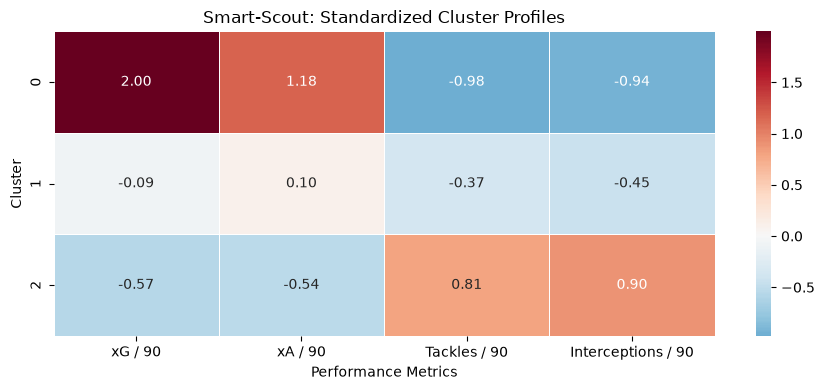

In [12]:
scaled_profiles = pd.DataFrame(
    scaler.transform(cluster_profiles),
    index=cluster_profiles.index,
    columns=MODEL_FEATURES
)

scaled_profiles.columns = [
    "xG / 90",
    "xA / 90",
    "Tackles / 90",
    "Interceptions / 90"
]

plt.figure(figsize=(9, 4))

sns.heatmap(
    scaled_profiles,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    linewidths=0.5
)

plt.title("Smart-Scout: Standardized Cluster Profiles")
plt.xlabel("Performance Metrics")
plt.ylabel("Cluster")
plt.tight_layout()
plt.show()

In [13]:
for cluster in sorted(df["cluster"].unique()):
    print(f"\nCLUSTER {cluster}")

    display(
        df[df["cluster"] == cluster][
            ["player_name", "minutes_played", *MODEL_FEATURES]
        ].sort_values(
            "minutes_played",
            ascending=False
        ).head(10)
    )


CLUSTER 0


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90
56,Enzo Fernández,3121,0.311439,0.199840,1.528356,0.605575
73,Morgan Gibbs-White,3110,0.300386,0.081318,0.578778,0.376206
60,Bruno Fernandes,3066,0.303229,0.378082,1.585127,0.587084
53,Florian Wirtz,2388,0.256658,0.186935,1.281407,0.414573
57,Phil Foden,2107,0.251590,0.194352,1.452302,0.384433
27,Cole Palmer,1965,0.501069,0.109008,1.145038,0.687023
2,Eberechi Eze,1900,0.229737,0.129789,0.900000,0.521053
58,Rayan Cherki,1794,0.197157,0.412876,1.304348,0.351171
21,Jack Hinshelwood,1750,0.243771,0.115200,0.977143,0.257143
12,David Brooks,1220,0.449262,0.235328,1.401639,0.295082



CLUSTER 1


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90
30,Morgan Rogers,3285,0.178630,0.112603,1.150685,0.356164
52,Dominik Szoboszlai,3233,0.129168,0.180668,1.558924,0.835138
1,Declan Rice,3099,0.088577,0.194288,2.032914,1.074540
43,Sander Berge,2911,0.046067,0.044830,1.762281,0.772930
77,Granit Xhaka,2903,0.030382,0.111299,1.550121,0.899070
79,Noah Sadiki,2894,0.043849,0.043227,1.430546,1.057360
11,Alex Scott,2859,0.115845,0.090031,1.888772,1.133263
51,Alexis Mac Allister,2675,0.125495,0.054168,1.783178,0.706542
38,Kiernan Dewsbury-Hall,2635,0.142087,0.176926,1.776091,0.409867
31,Adam Wharton,2562,0.051639,0.250117,2.459016,0.948478



CLUSTER 2


,player_name,minutes_played,scoring.expected_goals_per90,scoring.expected_assists_per90,defending.tackles_per90,defending.interceptions_per90
37,James Garner,3414,0.051406,0.149736,3.163445,1.555360
55,Elliot Anderson,3334,0.075315,0.123635,2.807439,1.106779
48,Ethan Ampadu,3123,0.068876,0.062824,2.334294,1.440922
83,Mateus Fernandes,3024,0.056548,0.083929,3.065476,1.041667
4,Martín Zubimendi,3001,0.081273,0.065078,2.039320,1.169610
54,Ryan Gravenberch,2996,0.054372,0.070294,1.772363,1.441923
8,João Gomes,2843,0.038621,0.063630,3.387267,1.139641
29,Moisés Caicedo,2802,0.044004,0.073233,2.794433,1.895075
89,André,2766,0.016269,0.031236,2.668113,0.976139
20,Yehor Yarmoliuk,2675,0.038355,0.044748,2.355140,0.942056


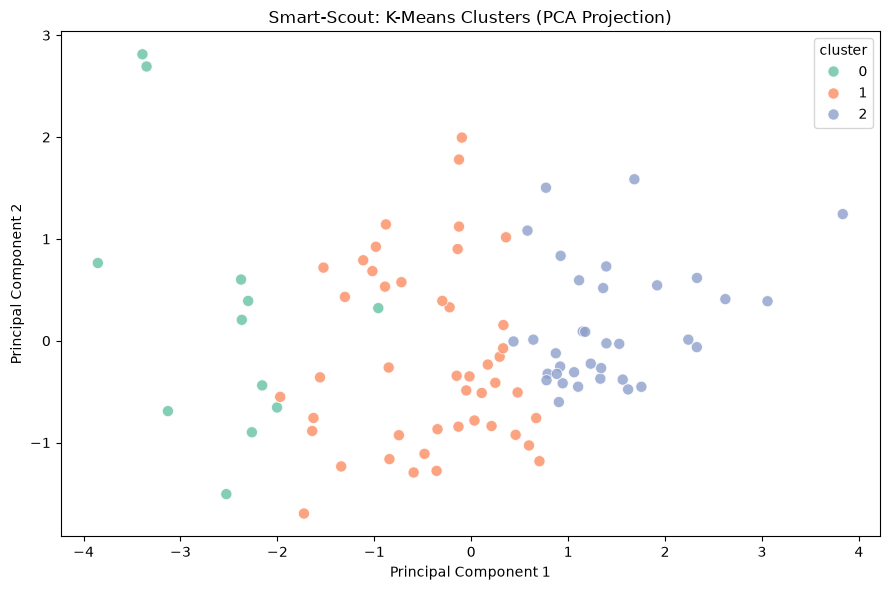

Explained variance: 0.7442021182688999


In [14]:
from sklearn.decomposition import PCA

X_scaled = scaler.transform(df[MODEL_FEATURES])

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(9, 6))

sns.scatterplot(
    x=X_pca[:, 0],
    y=X_pca[:, 1],
    hue=df["cluster"],
    palette="Set2",
    s=65,
    alpha=0.8
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Smart-Scout: K-Means Clusters (PCA Projection)")
plt.tight_layout()
plt.show()

print("Explained variance:", pca.explained_variance_ratio_.sum())

In [15]:
import numpy as np

X_scaled = scaler.transform(df[MODEL_FEATURES])

# Distance from each player to their assigned cluster centroid
distances = np.linalg.norm(
    X_scaled - kmeans.cluster_centers_[df["cluster"].to_numpy()],
    axis=1
)

representatives = df.copy()
representatives["distance_to_centroid"] = distances

for cluster in sorted(representatives["cluster"].unique()):
    print(f"\nCluster {cluster} - Representative Players")

    display(
        representatives[
            representatives["cluster"] == cluster
        ][
            ["player_name", "minutes_played", "distance_to_centroid"]
        ].sort_values("distance_to_centroid").head(5)
    )


Cluster 0 - Representative Players


,player_name,minutes_played,distance_to_centroid
53,Florian Wirtz,2388,0.456325
56,Enzo Fernández,3121,0.485767
57,Phil Foden,2107,0.574936
13,Justin Kluivert,951,1.204906
2,Eberechi Eze,1900,1.246121



Cluster 1 - Representative Players


,player_name,minutes_played,distance_to_centroid
68,Joe Willock,1011,0.366819
76,Chris Rigg,773,0.644615
34,Will Hughes,1577,0.693994
64,Mason Mount,1018,0.696419
90,Jean-Ricner Bellegarde,1251,0.782102



Cluster 2 - Representative Players


,player_name,minutes_played,distance_to_centroid
71,Nico González,1575,0.392324
75,Ryan Yates,629,0.451374
48,Ethan Ampadu,3123,0.451861
6,Amadou Onana,1776,0.549759
72,Ibrahim Sangaré,2080,0.557905


## Baseline Model Findings

The baseline K-Means model grouped 92 Premier League midfielders into three clusters using four standardized per-90 performance metrics: expected goals, expected assists, tackles, and interceptions.

The clusters exhibited distinct statistical profiles corresponding to attacking, intermediate, and defensive midfielders. Clusters show players with similar playing styles were frequently grouped together.

The model achieved a silhouette score of **0.245**, indicating modest cluster separation and some overlap between player profiles. PCA visualization further illustrated these relationships.